# 🐍 Análisis de Expresión Diferencial (RNA-seq) con **PyDESeq2**: Ejemplo práctico en células de Aedes aegypti infectadas con Chikungunya  🦟

**Duración:** 2 horas, aprox.

### 🎯 Objetivos del Taller

El objetivo general de este taller es que los participantes comprendan el flujo de trabajo típico de un análisis de RNA-seq, utilizando herramientas de Python, específicamente la librería **PyDESeq2**.

Al finalizar el taller, los participantes serán capaces de:

1. **Comprender el tren de trabajo completo de RNA-seq:** Identificar los pasos previos al análisis estadístico (control de calidad, alineamiento, cuantificación) y entender de dónde proviene la matriz de conteos que se utiliza como punto de partida.
2. **Realizar análisis exploratorio en Python:** Cargar una matriz de conteos real y visualizar la estructura global de las muestras.
3. **Ejecutar un análisis de expresión diferencial:** Utilizar PyDESeq2 para definir contrastes entre condiciones biológicas y obtener tablas de resultados.
4. **Filtrar e interpretar resultados:** Aplicar criterios estadísticos y biológicos (p-valor ajustado y log2FoldChange) para identificar genes significativos y visualizarlos graficamente.






Para este taller utilizaremos datos públicos reales de RNA-seq del proyecto:

**"Transcriptomics of *Aedes aegypti* derived Aag2 cells in response to chikungunya virus infection"**

- **Autores:** Dubey SK, Mehta D, Chaudhary S, Hasan A, Sunil S.
- **Institución:** International Centre for Genetic Engineering and Biotechnology (ICGEB), Nueva Delhi, India.
- **Accesión GEO:** [GSE195852](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE195852)
- **Diseño experimental:** Células Aag2 (derivadas de *Aedes aegypti*) fueron infectadas con el virus Chikungunya (CHIKV) y comparadas contra células no infectadas (control). El estudio incluye 6 muestras en total (3 réplicas biológicas por condición). Los datos fueron procesados por los autores usando STAR para alineamiento y featureCounts para la cuantificación.
- **Publicación asociada:**
Dubey, S. K., Mehta, D., Chaudhary, S., Hasan, A., & Sunil, S. (2022). An E3 Ubiquitin Ligase Scaffolding Protein Is Proviral during Chikungunya Virus Infection in Aedes aegypti. Microbiology spectrum, 10(3), e0059522. https://doi.org/10.1128/spectrum.00595-22


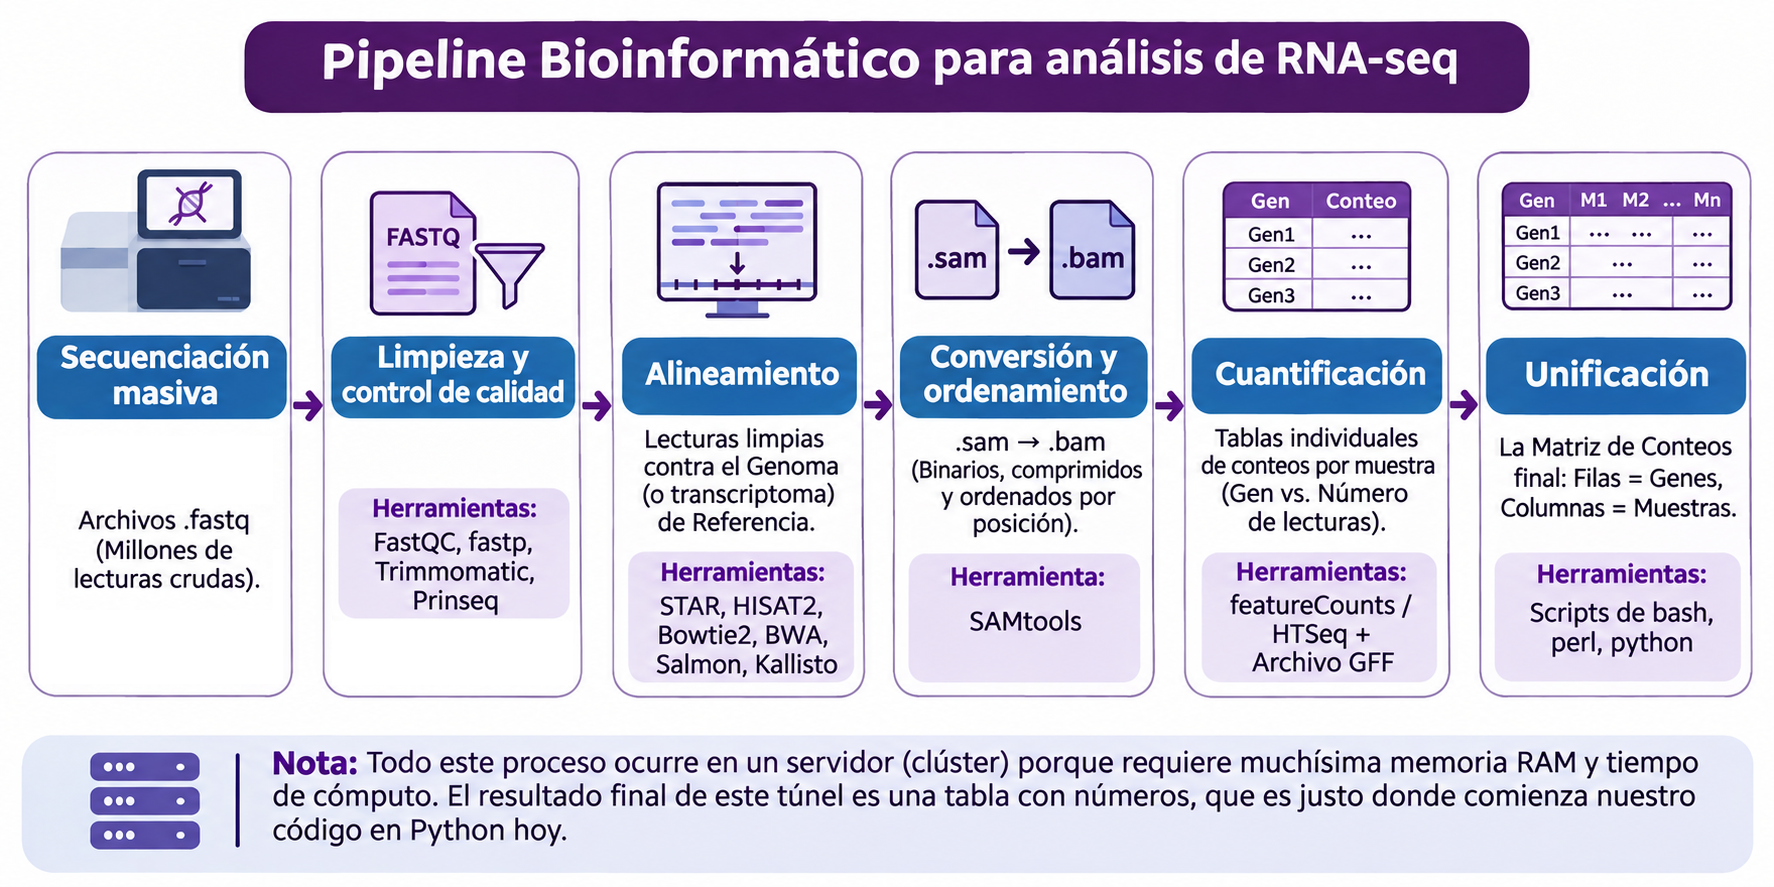

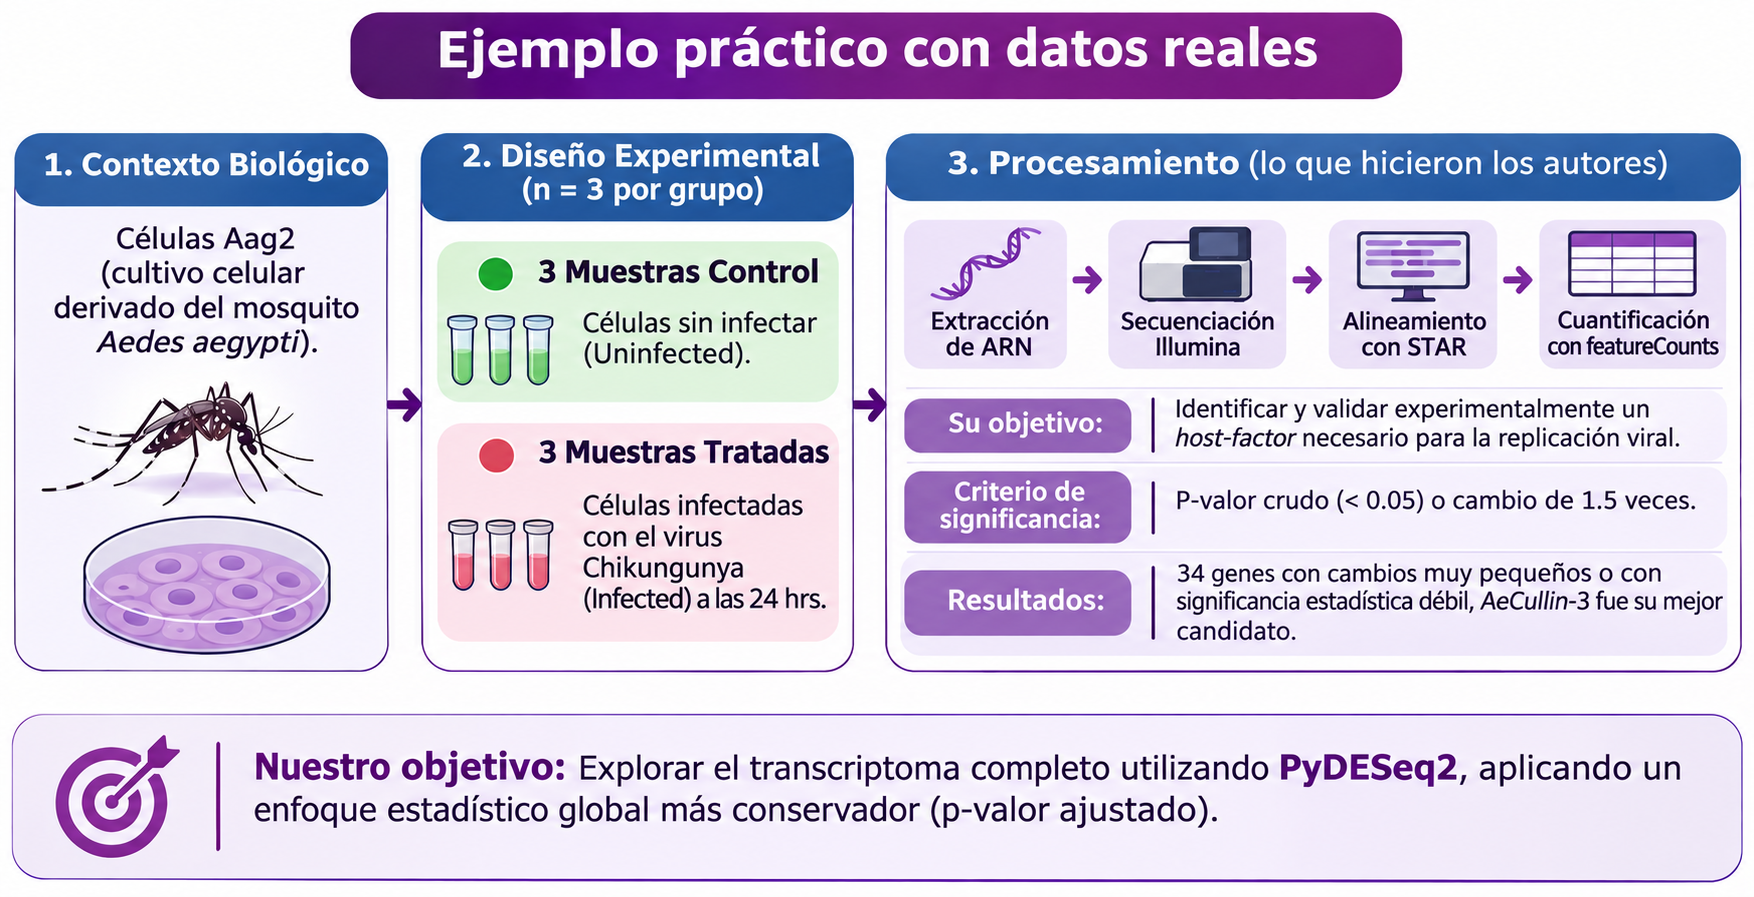

In [ ]:
# Instalar versiones exactas de pandas, anndata y pydeseq para evitar incompatibilidad de versiones
!pip install --quiet "pandas==2.2.3" "anndata==0.12.6" "pydeseq2==0.5.4"

In [ ]:
#  Importar librerías
import pandas as pd
import numpy as np
import glob
import os
import matplotlib.pyplot as plt
import seaborn as sns
from pydeseq2.dds import DeseqDataSet   # Objeto central del análisis: guarda conteos, metadatos y parámetros del modelo
from pydeseq2.ds import DeseqStats      # Realiza la prueba estadística (Wald) y genera la tabla de resultados
from sklearn.decomposition import PCA   # Para el análisis exploratorio

In [ ]:
# Montar Google Drive
from google.colab import drive
drive.mount('/content/drive')
# Modificar segun la dirección de drive donde hayan subido los archivos
path_drive = "/content/drive/MyDrive/pyladies_Nov2026/data/"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 🛠️ Paso 0: Generar matriz unificada de conteos

En el flujo de trabajo típico, se ejecuta un **pipeline** en el clúster o servidor utilizando herramientas bioinformaticas desde de línea de comandos. Ese flujo previo parte de los datos de secuenciación masiva (RNA-seq), que son procesados secuencialmente por distintas herramientas hasta generar  **una tabla de conteos por cada muestra** .

**El formato general de estos archivos:**
- Tienen una columna con el identificador del gen (ej. `gene_id` o `Geneid`).

- Columnas con el número de lecturas (reads) asignadas a ese gen.

- **Columnas adicionales:** Dependen de la herramienta. Algunas (como `featureCounts`) agregan metadatos como el cromosoma, las coordenadas de inicio/fin y la longitud del gen. Otras (como `HTSeq`) solo arrojan el gen y el conteo.

En muchos casos, la salida "cruda" de estas herramientas contiene múltiples columnas que no necesitamos para el análisis estadístico. Por eso, es común usar scripts en Bash, Perl o Python en el clúster para extraer únicamente dos columnas: el identificador del gen y el conteo.

**El código que veremos a continuación:**
1. Busca todos los archivos individuales en la carpeta "data".
2. Extrae las columans de interés.
3. Une todas las muestras en una sola matriz.


 Nota: Es importante conocer el formato de las tablas individuales para poder seleccionar las columnas correctas, ya que el numero de columnas y orden en el que aparecen varía según la herramienta con la que se hayan generado

In [ ]:
# 1. Buscar todos los archivos de conteos en la carpeta data/
archivos = glob.glob(f"{path_drive}/GSM*.txt")

# 2. Leer y unificar
lista_conteos = [] #Lista vacía para almacenar las tablas individuales
for archivo in archivos:
    # Extraer el ID de la muestra (ej. "GSM5852172")
    nombre_muestra = os.path.basename(archivo).split("_")[0]
    # Como buena práctica, se recomienda usar nombres de archivo descriptivos
    # que permitan identificar fácilmente a qué muestra corresponde cada uno.
    # En el dataset de ejemplo tenemos: GSM5852172_Uninfected-1tablar.txt
    # donde:
    #   - GSM5852172: es el ID de la muestra en GEO.
    #   - Uninfected-1: indica la condición y el número de réplica biológica.

    # Leer el archivo
    df = pd.read_csv(archivo, sep="\t", header=None, index_col=1)
    # Extraer SOLO la última columna (conteos) y ponerle el nombre de la muestra
    # Al usar index_col=1, la columna de conteos ahora es la columna -1 (la última).
    lista_conteos.append(df.iloc[:, -1].rename(nombre_muestra))

# Unir todo en una sola matriz (genes en filas, muestras en columnas)
counts_df = pd.concat(lista_conteos, axis=1)

# 3. Guardar la matriz unificada
counts_df.to_csv(f"{path_drive}/counts.csv", index_label="Gene_ID")
print(f"Matriz guardada: {counts_df.shape[0]} genes, {counts_df.shape[1]} muestras.")

Matriz guardada: 19804 genes, 6 muestras.


## 1.- CARGAR TABLA DE CONTEOS UNIFICADA 📂

**⚠️  Esta sección puede cambiar según el dataset que se use.**

El notebook asume que en el repositorio del taller existe una carpeta `data/` con dos archivos:

- `data/counts.csv`: matriz de conteos crudos. **Genes en filas, muestras en columnas.** Valores enteros no negativos.
- `data/metadata.csv`: metadatos de las muestras. **Muestras en filas.** Debe tener al menos una columna llamada `condition` con los nombres de los grupos (ej. `control`, `tratado`).

Si el dataset cambia, solo hay que ajustar las rutas, el nombre de la columna de condición y los nombres de los niveles en el contraste (más abajo).

In [ ]:
# Ajusta estas rutas si tu dataset tiene otro nombre o ubicación
counts_path= f"{path_drive}/counts.csv" #Path a la tabla de conteos en formato .csv
meta_path= f"{path_drive}/metadata.csv" #Path a la tabla con información de las muestras analizadas

#Leer tablas
counts_df = pd.read_csv(counts_path, index_col=0)
metadata_df = pd.read_csv(meta_path, index_col=0)

print("Dimensiones de la matriz de conteos (genes x muestras):", counts_df.shape)
print("Dimensiones de los metadatos (muestras x variables):", metadata_df.shape)
print("\nPrimeras filas de los conteos:")
print(counts_df.head())
print("\nMetadatos:")
print(metadata_df.head())

Dimensiones de la matriz de conteos (genes x muestras): (19804, 6)
Dimensiones de los metadatos (muestras x variables): (6, 3)

Primeras filas de los conteos:
            GSM5852172  GSM5852176  GSM5852175  GSM5852173  GSM5852177  \
Gene_ID                                                                  
AAEL000001        1341        1080         831        1233         790   
AAEL000004        5443        3844        2692        3329        4752   
AAEL000005         119         171         162         195         176   
AAEL000006         635          82         123         322        1139   
AAEL000008         935        1005         984         908        1143   

            GSM5852174  
Gene_ID                 
AAEL000001        1826  
AAEL000004       10427  
AAEL000005         419  
AAEL000006        2675  
AAEL000008        2518  

Metadatos:
             condition infection_time  replica
sampleID                                      
GSM5852172  Uninfected            NaN    

## 2.- Normalización de datos 📏

**El problema:** En RNA-seq, no todas las muestras se secuencian con la misma profundidad (ej. una puede tener 20 millones de lecturas y otra 30 millones). Si comparamos los conteos crudos, las muestras con más lecturas parecerán tener una expresión artificialmente alta debida a diferencias técnicas por la profundidad de secuenciación en lugar de mostrar diferencias biológicas reales. La normalización es el proceso matemático para corregir este sesgo técnico.

### Conceptos estadísticos de normalización
Independientemente del software que uses, existen distintos supuestos matemáticos para normalizar:

1. **Normalización total (ej. CPM - Counts Per Million):** Divide los conteos de cada gen entre el total de lecturas de esa muestra. Es muy simple, pero asume que el total de lecturas representa la misma cantidad de ARN en todas las muestras (algo que no siempre es cierto si hay genes muy dominantes).
2. **Mediana de ratios (Median-of-ratios):** En lugar de usar el total, calcula una "media geométrica" de referencia para cada gen y ve qué tanto se desvía cada muestra de esa referencia. Asume que **la mayoría de los genes no cambian** entre condiciones. Es el estándar de oro para análisis diferencial.
3. **Media recortada (ej. TMM):** Similar al anterior, pero ignora los genes con expresión extrema (los muy altos y los muy bajos) para calcular el factor de escala, haciéndolo más robusto.

### ¿Cómo se aplica esto en PyDESeq2?

En este taller haremos una distinción crucial:

1. **Para el análisis exploratorio (PCA):** Usaremos la normalización total **CPM** y una transformación logarítmica (`log2(CPM + 1)`). ¿Por qué? Porque es rápida, visualmente efectiva y nos permite ver si las muestras se agrupan sin que la profundidad de secuenciación domine el gráfico.
2. **Para el análisis diferencial:** **No normalizaremos manualmente.** PyDESeq2 aplicará el método de **mediana de ratios** de forma interna cuando ejecutemos el modelo. El algoritmo necesita los **conteos crudos enteros** para poder calcular la varianza estadística (distribución binomial negativa). Si le pasamos datos pre-normalizados (como CPM), el modelo fallará o dará resultados inválidos.


In [ ]:
# Normalización con CPM (Counts Per Million)
# 1. Calcular el total de lecturas (profundidad) por cada muestra (columna)
profundidad_muestras = counts_df.sum(axis=0)

# 2. Dividir cada conteo entre la profundidad de su muestra y multiplicar por 1,000,000
cpm = counts_df.div(profundidad_muestras, axis=1) * 1e6

# 3. Transformación logarítmica para estabilizar la varianza (sumamos 1 para evitar log(0))
log_cpm = np.log2(cpm + 1)

print("Dimensiones de la matriz normalizada (log2 CPM):", log_cpm.shape)
print("\nPrimeras filas de log2(CPM + 1):")
print(log_cpm.head())

Dimensiones de la matriz normalizada (log2 CPM): (19804, 6)

Primeras filas de log2(CPM + 1):
            GSM5852172  GSM5852176  GSM5852175  GSM5852173  GSM5852177  \
Gene_ID                                                                  
AAEL000001    6.393626    6.211968    5.895955    6.237122    5.203161   
AAEL000004    8.401729    8.029483    7.574866    7.657946    7.758744   
AAEL000005    3.065601    3.652919    3.633836    3.674870    3.167419   
AAEL000006    5.334099    2.712022    3.272888    4.353202    5.718954   
AAEL000008    5.880787    6.109584    6.135993    5.802543    5.723916   

            GSM5852174  
Gene_ID                 
AAEL000001    5.360271  
AAEL000004    7.844571  
AAEL000005    3.349971  
AAEL000006    5.899933  
AAEL000008    5.814178  


## 2.- Análisis exploratorio 🔍

Antes de analizar la expresión diferencial, conviene ver cómo se distribuyen los conteos entre muestras y si hay estructura global (por ejemplo, separación por condición) mediante un PCA.

Con los datos ya normalizados (log2 CPM), revisamoslo siguiente:
1.
2.
3.

nota: Dejo espacio para las graficas que  ustedes prefieran, solo les explico como estan estryucturados los datos hasta este punto


In [ ]:
# En este punto del notebook ya se cargaron los datos y se calculó la
# normalización para exploración. Aún no se ha tocado PyDESeq2.
# El objetivo de esta sección es puramente visual y de control de calidad.

# Lo que ya está cargado en la memoria de Python:
# 1. counts_df
#    - Estructura: Filas = Genes (ej. "AAEL000001"), Columnas = Muestras (ej. "GSM5852172").
#    - Contenido: Números enteros que representan la cantidad de lecturas (reads).
#      NO están normalizadas.
#
# 2. metadata_df
#    - Estructura: Filas = Muestras (los mismos IDs que las columnas de counts_df).
#    - Contenido: Información descriptiva de cada muestra. Las columnas son:
#         * "condition": Indica el grupo ("Uninfected" o "Infected").
#         * "infection_time": Indica el tiempo (ej. "24hrs").
#         * "replica": Número de réplica (1, 2 o 3).
#
# 3. cpm y log_cpm
#    - Estructura: Exactamente igual que counts_df (Filas = Genes, Columnas = Muestras).
#    - Contenido:
#         * "cpm": Conteos normalizados (Counts Per Million) para corregir la
#           profundidad de secuenciación.
#         * "log_cpm": Es el logaritmo base 2 de "cpm" + 1.


# OPCIONES DE VISUALIZACIÓN COMÚNMENTE USADAS EN LA LITERATURA:
# 1. Boxplot de distribución:
#    - Gráfica: seaborn.boxplot(data=log_cpm.T)
#    - Uso: Ver si alguna muestra tiene una distribución atípica.
#
# 2. PCA (Análisis de Componentes Principales):
#    - Gráfica: sklearn.decomposition.PCA(n_components=2).fit_transform(log_cpm.T)
#    - Uso: Ver si las muestras se agrupan por condición biológica o detectar outliers.
#
# 3. Heatmap de correlación:
#    - Gráfica: seaborn.heatmap(log_cpm.corr(), annot=True, cmap="vlag")
#    - Uso: Validar que las réplicas biológicas correlacionan alto entre sí.
#
# 4. Profundidad de secuenciación (Barplot):
#    - Gráfica: seaborn.barplot(x=counts_df.columns, y=counts_df.sum(axis=0))
#    - Uso: Visualizar el total de lecturas crudas por muestra.
#
# 5. Dendrograma de agrupamiento jerárquico:
#    - Gráfica: scipy.cluster.hierarchy.dendrogram o seaborn.clustermap
#    - Uso: Ver el agrupamiento de las muestras sin forzar la reducción a 2D del PCA.


## 🧪 Análisis de expresión diferencial con PyDESeq2

PyDESeq2 implementa el modelo de DESeq2: ajusta un modelo lineal generalizado con distribución binomial negativa, estima la dispersión y prueba diferencias entre condiciones mediante una prueba de Wald.

**Entrada esperada:** matriz de conteos **crudos** con **muestras en filas y genes en columnas** (al contrario que nuestra `counts_df`, que tiene genes en filas). Por eso transponemos.

**⚠️ Importante:** usar los conteos crudos (`counts_df`), NO la matriz normalizada (`cpm` o `log_cpm`). PyDESeq2 calcula sus propios factores de tamaño internamente (normalización por mediana de ratios).

In [ ]:
# Filtrar genes con baja expresión (ej. menos de 10 lecturas en total)
umbral_lecturas = 10
counts_filtrado = counts_df[counts_df.sum(axis=1) >= umbral_lecturas].copy()

print(f"Genes originales: {counts_df.shape[0]}")
print(f"Genes filtrados: {counts_filtrado.shape[0]}")

Genes originales: 19804
Genes filtrados: 12920


In [ ]:
# transponer matríz. PyDESeq2 espera muestras en filas y genes en columnas.
counts_for_deseq = counts_filtrado.T

In [ ]:
# Alineación de indices: ¿Son exactamente iguales en orden y contenido?
#PyDESeq2 utiliza una estructura interna llamada `AnnData` que requiere que los rownames de
#de la matriz de conteos (que ahora son nuestras muestras, ya que transpusimos la tabla)
#sea exactamente igual a los rownames del metadata.
if counts_for_deseq.index.equals(metadata_df.index):
    print("Los índices de la matriz y el metadata coinciden.")
else:
    # Buscar diferencias en contenido
    solo_en_matriz = set(counts_for_deseq.index) - set(metadata_df.index)
    solo_en_metadata = set(metadata_df.index) - set(counts_for_deseq.index)
    if solo_en_matriz or solo_en_metadata:
        print("Faltan nombres en alguno de los datasets:")
        print(f" - Nombres en la matriz que no están en el metadata: {solo_en_matriz}")
        print(f" - Nombres en el metadata que no están en la matriz: {solo_en_metadata}")
    else:
        print("Los índices de la matriz y el metadata están en desorden.")


Los índices de la matriz y el metadata están en desorden.


In [ ]:
# Solución: Ordenar ambos índices alfabéticamente para asegurar que coincidan
counts_for_deseq = counts_for_deseq.sort_index()
metadata_df = metadata_df.sort_index()

### Ejecución del modelo
El método `deseq2()` realiza tres pasos internos:
1. Calcula los **factores de tamaño** (la normalización interna).
2. Estima la **dispersión** (la variabilidad de cada gen y la variabilidad global del experimento).
3. Ajusta el **GLM** (Modelo Lineal Generalizado) a los datos.

In [ ]:
# Drear objeto Deseq
dds = DeseqDataSet(
    counts=counts_for_deseq,
    metadata=metadata_df,
    design_factors="condition",
    refit_cooks=True,
    n_cpus=1
)

print("DeseqDataSet creado correctamente.")

DeseqDataSet creado correctamente.


/tmp/ipykernel_23777/2459268606.py:2: DeprecationWarning: design_factors is deprecated and will soon be removed.Please consider providing a formulaic formula using the design argumentinstead.
  dds = DeseqDataSet(


In [ ]:
# Ejecutar el análisis
# dds.deseq2() calcula internamente: factores de tamaño (normalización RLE),
# dispersiones (común y por gen) y ajusta el modelo GLM.
dds.deseq2()
print("Análisis de dispersión completado.")

Fitting size factors...
... done in 0.01 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 31.73 seconds.

Fitting dispersion trend curve...
... done in 0.47 seconds.

Fitting MAP dispersions...
... done in 34.02 seconds.

Fitting LFCs...


Análisis de dispersión completado.


... done in 12.71 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.



### Comparación entre condiciones

Para definir las grupos a comparar en PyDESeq2, se define una lista con tres elementos: `["variable", "grupo_de_interés", "grupo_de_referencia"]`.

- **`"variable"`**: el nombre de la columna de los metadatos que define los grupos (en este notebook, `"condition"`).
- **`"grupo_de_interés"`**: es el grupo "problema" del cual se desea conocer si existen cambios con respecto al control.
- **`"grupo_de_referencia"`**: es el control grupo contra el que comparas.

Por ejemplo, con `["condition", "tratado", "control"]`, el análisis calcula el **log2FoldChange de "tratado" respecto a "control"**. Un valor positivo significa mayor expresión en "tratado"; uno negativo, mayor expresión en "control".

Es importante tener claro cuál es el grupo de interés y cuál la referencia, porque **el signo del log2FoldChange depende del orden**. Si intercambias los dos grupos, todos los signos se invierten.

In [ ]:
# El contraste es [variable, grupo_de_interes, grupo_de_referencia].
# log2FoldChange > 0 significa mayor expresión en el grupo_de_interes.
#  "tratado" y "control" son los nombres que se asignaron para este ejemplo,
# y puede variar las condiciones de tu condiciones de tu experimento.
grupo_de_interes = "Infected"
grupo_de_referencia = "Uninfected"

# Ejecutar prueba
stat_res = DeseqStats(dds, contrast=["condition", grupo_de_interes, grupo_de_referencia],
                      independent_filter=True, alpha=0.05  )
stat_res.summary()

# Extraer la tabla de resultados
results_df = stat_res.results_df

print("\nPrimeras filas de los resultados (genes con mayor cambio positivo):")
print(results_df.sort_values("log2FoldChange", ascending=False).head())

Running Wald tests...


Log2 fold change & Wald test p-value: condition Infected vs Uninfected
               baseMean  log2FoldChange     lfcSE      stat    pvalue  \
Gene_ID                                                                 
AAEL000001  1214.085789       -0.324649  0.486595 -0.667186  0.504653   
AAEL000004  4656.326074       -0.274994  0.319257 -0.861355  0.389043   
AAEL000005   194.677725        0.056486  0.398842  0.141624  0.887377   
AAEL000006   569.382334       -0.934129  0.761686 -1.226396  0.220050   
AAEL000008  1164.757186        0.111901  0.290312  0.385452  0.699903   
...                 ...             ...       ...       ...       ...   
AAEL029102   897.478723        0.047799  0.216041  0.221251  0.824897   
AAEL029104     1.993262        0.871999  1.662228  0.524596  0.599864   
AAEL029108     2.653187       -2.059198  1.724109 -1.194355  0.232339   
AAEL029115     2.470042       -0.514913  1.484011 -0.346974  0.728611   
AAEL029117  1270.400966        0.335855  0.636964  0.

... done in 9.20 seconds.



## ✅ Criterios de significancia

Para decidir qué genes están diferencialmente expresados se combinan dos criterios:

1. **`padj` (p-valor ajustado):** controla la tasa de falsos positivos cuando se prueban miles de genes a la vez. El umbral habitual es `padj < 0.05`. Un valor menor indica mayor evidencia estadística de que el cambio no es ruido.
2. **`log2FoldChange` (magnitud del cambio):** indica cuánto cambia la expresión entre grupos. Un valor de 1 equivale a duplicarse (2¹), y -1 a reducirse a la mitad. El umbral habitual es `|log2FoldChange| > 1`, es decir, al menos el doble o la mitad.

**¿Por qué usar ambos?** Porque con muchas muestras o genes, un cambio minúsculo puede salir estadísticamente significativo (`padj` bajo) pero no tener relevancia biológica. Y al revés: un cambio grande puede no ser significativo si hay mucha variabilidad. Combinar los dos criterios filtra genes que son **a la vez** estadísticamente sólidos y biológicamente relevantes.

Estos umbrales son convencionales y ajustables. En un análisis real conviene justificarlos según el diseño experimental y el objetivo biológico.

In [ ]:
# Filtrar genes significativos
padj_cutoff = 0.5  # umbral de significancia estadística (p-valor ajustado)
lfc_cutoff = 0.5     # umbral de magnitud del cambio (|log2FoldChange|)

significant = results_df[
    (results_df["padj"] < padj_cutoff) &
    (results_df["log2FoldChange"].abs() > lfc_cutoff)
].copy()

up = significant[significant["log2FoldChange"] > 0]
down = significant[significant["log2FoldChange"] < 0]

print(f"Genes significativos totales: {len(significant)}")
print(f"Sobreexpresados en {grupo_de_interes}: {len(up)}")
print(f"Subexpresados en {grupo_de_interes}: {len(down)}")

print("Top 10 genes por log2FoldChange (mayor sobreexpresión):")
print(up.sort_values("log2FoldChange", ascending=False).head(10))

Genes significativos totales: 52
Sobreexpresados en Infected: 27
Subexpresados en Infected: 25
Top 10 genes por log2FoldChange (mayor sobreexpresión):
               baseMean  log2FoldChange     lfcSE      stat        pvalue  \
Gene_ID                                                                     
AAEL025356   314.489760        5.171034  1.041977  4.962713  6.951531e-07   
AAEL007302   154.951986        3.623067  1.107040  3.272752  1.065058e-03   
AAEL022732    64.852337        3.605419  0.935766  3.852905  1.167245e-04   
AAEL023677    89.993699        3.438185  1.006575  3.415727  6.361199e-04   
AAEL017994    37.253189        3.399453  1.037125  3.277766  1.046321e-03   
AAEL021605    70.415648        3.341065  0.991569  3.369474  7.531177e-04   
AAEL014246  1166.428910        2.919737  0.675274  4.323778  1.533793e-05   
AAEL010500  3261.970573        2.915207  0.692129  4.211939  2.531882e-05   
AAEL021780    96.546962        2.890317  0.731964  3.948714  7.857206e-05   
AA

In [ ]:
!pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 18.3 MB/s  0:00:00


In [ ]:
# 1. Cargar el archivo de BioMart
ruta_biomart = f"{path_drive}/Aedes_aegypti_Biomart.txt"
anotacion = pd.read_csv(ruta_biomart, sep="\t")

# 2. Poner el ID del gen como índice
anotacion = anotacion.set_index("Gene_ID")

# 3. Unir con tus resultados
significant_final = significant.join(anotacion, how="left")

# 4. Rellenar los nombres vacíos (NaN) con el ID del gen (usando apply)
significant_final["Gene_name"] = significant_final.apply(
    lambda row: row.name if pd.isna(row["Gene_name"]) else row["Gene_name"], axis=1
)

# 5. Mostrar la tabla final
print("20 genes significativos con su anotación")
columnas_mostrar = ["Gene_name", "Gene_description", "log2FoldChange", "padj"]
print(significant_final[columnas_mostrar].sort_values("log2FoldChange", ascending=False).head(15))

20 genes significativos con su anotación
             Gene_name                          Gene_description  \
Gene_ID                                                            
AAEL025356  AAEL025356                                       NaN   
AAEL007302  AAEL007302                                       NaN   
AAEL022732  AAEL022732                                       NaN   
AAEL023677  AAEL023677                                       NaN   
AAEL017994  AAEL017994                                       NaN   
AAEL021605  AAEL021605                                       NaN   
AAEL014246  AAEL014246        glucosyl/glucuronosyl transferases   
AAEL010500       GSTX2                   glutathione transferase   
AAEL021780  AAEL021780                                       NaN   
AAEL005109  AAEL005109                         WD-repeat protein   
AAEL020299  AAEL020299                                       NaN   
AAEL006271      CUSOD2  copper-zinc (Cu-Zn) superoxide dismutase   
AAEL001

In [ ]:
# Por si quieren agregar graficas:
# Contexto:
# Ya se realizo el análisis estadístico. Ahora tenemos una tabla con todos los
# genes y qué tanto cambiaron entre nuestras muestras infectadas y las sanas.
# El Volcano Plot ya muestra el panorama general, pero estas gráficas ayudan
# a interpretar los resultados desde otras perspectivas.
#
# VARIABLES DE ENTRADA DISPONIBLES EN MEMORIA:
#
# 1. results_df
#    - Tabla completa de resultados del análisis.
#    - Columnas clave:
#         * "log2FoldChange": Magnitud del cambio (positivo = más expresado en infectados).
#         * "padj": Significancia estadística ajustada.
#         * "baseMean": Nivel de expresión promedio del gen en todas las muestras.
#    - Nota: Contiene todos los genes, significativos o no.
#
# 2. significant
#    - Es un subconjunto de `results_df`. Solo contiene los genes que
#      pasaron nuestros filtros (padj < 0.05 y |log2FoldChange| > 1).
#
# 3. counts_df y log_cpm
#    - Las matrices de expresión que ya usamos antes (crudas y normalizadas).
#
#
# OPCIONES DE VISUALIZACIÓN COMÚNMENTE USADAS EN LA LITERATURA:
# 1. MA Plot (Gráfico de dispersión de medias):
#    - Gráfica: plt.scatter(x=np.log10(results_df["baseMean"]),
#                           y=results_df["log2FoldChange"])
#    - Uso: Ver si el cambio (log2FC) depende de qué tan expresado esté el gen
#      (baseMean). Los genes con expresión muy baja suelen tener mucho ruido.
#
# 2. Heatmap de genes significativos (Clustermap):
#    - Gráfica: seaborn.clustermap(log_cpm.loc[significant.index],
#                                  col_colors=metadata_df["condition"], z_score=0)
#    - Uso: Ver patrones de expresión coordinada. Agrupa los genes que se
#      comportan igual y las muestras que se parecen.
#
# 3. Gráfico de barras de los "Top Hits":
#    - Gráfica: seaborn.barplot o seaborn.stripplot usando
#               log_cpm.loc[top_10_genes] agrupado por metadata_df["condition"].
#    - Uso: Ver cómo se comportan los 10 genes con el cambio más drástico
#      (los primeros de la lista de `significant`).
#
# 4. Histograma de p-valores:
#    - Gráfica: plt.hist(results_df["pvalue"], bins=50)
#    - Uso: Es un gráfico de control. Si el modelo estadístico está bien ajustado,
#      debería haber una "montaña" cerca de 0 (los genes que sí cambian) y el
#      resto distribuido de forma plana.
